<a href="https://colab.research.google.com/github/MuBasHarAkBar/Machine-Learning-Experiment-/blob/main/experiment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -i https://pypi.tuna.tsinghua.edu.cn/simple numpy matplotlib scikit-learn

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple


X_train shape: (84, 2)
X_test shape : (36, 2)
y_train shape: (84,)
y_test shape : (36,)


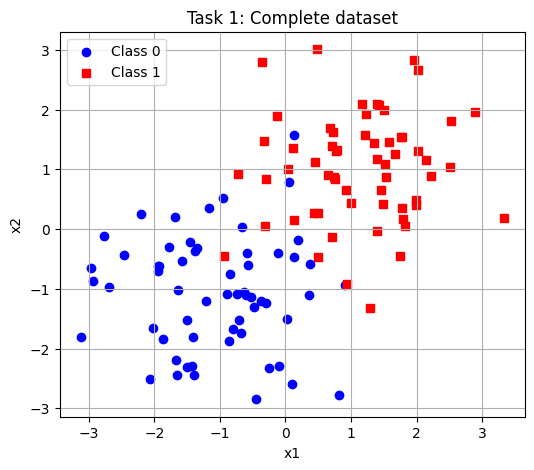

In [2]:
# Task 1
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(11)

mean_class0 = [-1.2, -1.0]
mean_class1 = [1.2, 1.0]
covariance = [[1, 0],
              [0, 1]]

X_class0 = rng.multivariate_normal(mean_class0, covariance, 60)
X_class1 = rng.multivariate_normal(mean_class1, covariance, 60)

y_class0 = np.zeros(60)
y_class1 = np.ones(60)

X = np.vstack((X_class0, X_class1))
y = np.concatenate((y_class0, y_class1))

indices = rng.permutation(120)
X = X[indices]
y = y[indices]

X_train = X[:84]
X_test = X[84:]
y_train = y[:84]
y_test = y[84:]

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

plt.figure(figsize=(6, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color="blue", marker="o", label="Class 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], color="red", marker="s", label="Class 1")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Task 1: Complete dataset")
plt.legend()
plt.grid(True)
plt.savefig("task1_scatter.png", dpi=300)
plt.show()

In [3]:
# Task 2
import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print("sigmoid(0)  =", sigmoid(0))
print("sigmoid(2)  =", round(sigmoid(2), 3))
print("sigmoid(-2) =", round(sigmoid(-2), 3))

def cross_entropy(y, p):

    p = np.clip(p, 1e-12, 1 - 1e-12)
    loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    return loss


p_test = np.array([0.8])

loss_y1 = cross_entropy(np.array([1]), p_test)
loss_y0 = cross_entropy(np.array([0]), p_test)

print("Loss for p = 0.8, y = 1:", loss_y1)
print("Loss for p = 0.8, y = 0:", loss_y0)

w = np.array([0.0, 0.0])
b = 0.0

z = X_train @ w + b

p_train = sigmoid(z)

initial_loss = cross_entropy(y_train, p_train)

print("First 5 probabilities:", p_train[:5])
print("Initial training cross-entropy:", initial_loss)
print("ln(2) for comparison          :", np.log(2))

sigmoid(0)  = 0.5
sigmoid(2)  = 0.881
sigmoid(-2) = 0.119
Loss for p = 0.8, y = 1: 0.2231435513142097
Loss for p = 0.8, y = 0: 1.6094379124341005
First 5 probabilities: [0.5 0.5 0.5 0.5 0.5]
Initial training cross-entropy: 0.6931471805599454
ln(2) for comparison          : 0.6931471805599453


Final w = [1.90777417 1.77614249]
Final b = -0.12840329206787948
First loss (iteration 1)    : 0.6931471805599454
Last recorded loss (iter 1000): 0.18567986558928976
Loss after the final update : 0.18567971180083792


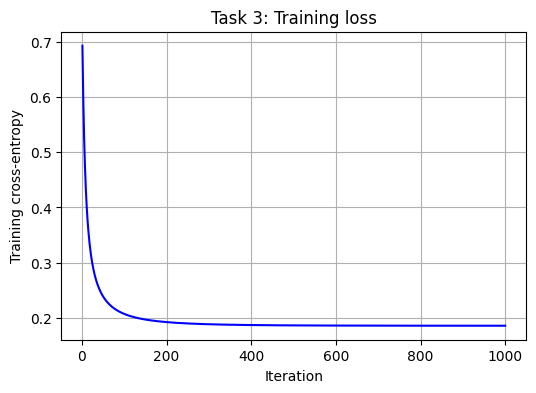

Training accuracy: 0.9523809523809523
Test accuracy    : 0.9444444444444444


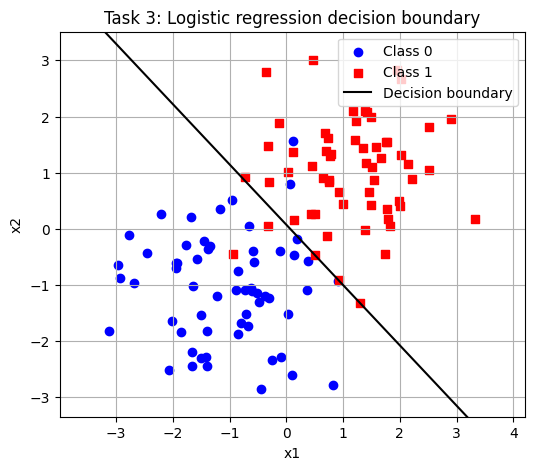


--- Special test observations ---
Closest to 0.5
  test index        : 2
  features          : [ 1.28952849 -1.31721822]
  true label        : 1
  predicted prob    : 0.49803966213631035
  predicted label   : 0
  score z           : -0.007841391633424802
  signed distance   : -0.0030083009660527536
Largest probability
  test index        : 33
  features          : [2.89295555 1.96167821]
  true label        : 1
  predicted prob    : 0.9998601671037605
  predicted label   : 1
  score z           : 8.874922603877046
  signed distance   : 3.4048086731291014
Smallest probability
  test index        : 27
  features          : [-2.07034064 -2.5143835 ]
  true label        : 0
  predicted prob    : 0.0001946624061082318
  predicted label   : 0
  score z           : -8.54404906911869
  signed distance   : -3.2778711063313937


In [5]:
# Task 3
import numpy as np
import matplotlib.pyplot as plt

w = np.array([0.0, 0.0])
b = 0.0
eta = 0.1
num_iterations = 1000
n = len(y_train)

loss_history = []

for i in range(num_iterations):

    z = X_train @ w + b
    p = sigmoid(z)


    loss = cross_entropy(y_train, p)
    loss_history.append(loss)


    error = p - y_train
    grad_w = (X_train.T @ error) / n
    grad_b = np.mean(error)


    w = w - eta * grad_w
    b = b - eta * grad_b


print("Final w =", w)
print("Final b =", b)
print("First loss (iteration 1)    :", loss_history[0])
print("Last recorded loss (iter 1000):", loss_history[-1])
print("Loss after the final update :", cross_entropy(y_train, sigmoid(X_train @ w + b)))


plt.figure(figsize=(6, 4))
plt.plot(range(1, num_iterations + 1), loss_history, color="blue")
plt.xlabel("Iteration")
plt.ylabel("Training cross-entropy")
plt.title("Task 3: Training loss")
plt.grid(True)
plt.savefig("task3_loss.png", dpi=300)
plt.show()


p_train = sigmoid(X_train @ w + b)
p_test = sigmoid(X_test @ w + b)

y_pred_train = (p_train >= 0.5).astype(int)
y_pred_test = (p_test >= 0.5).astype(int)

train_accuracy = np.mean(y_pred_train == y_train)
test_accuracy = np.mean(y_pred_test == y_test)

print("Training accuracy:", train_accuracy)
print("Test accuracy    :", test_accuracy)


plt.figure(figsize=(6, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color="blue", marker="o", label="Class 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], color="red", marker="s", label="Class 1")


x1_line = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 100)
x2_line = -(w[0] * x1_line + b) / w[1]
plt.plot(x1_line, x2_line, color="black", label="Decision boundary")

plt.ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Task 3: Logistic regression decision boundary")
plt.legend()
plt.grid(True)
plt.savefig("task3_boundary.png", dpi=300)
plt.show()

z_test = X_test @ w + b
distance = z_test / np.linalg.norm(w)

index_closest = np.argmin(np.abs(p_test - 0.5))
index_largest = np.argmax(p_test)
index_smallest = np.argmin(p_test)

print("\n--- Special test observations ---")
for name, idx in [("Closest to 0.5", index_closest),
                  ("Largest probability", index_largest),
                  ("Smallest probability", index_smallest)]:
    print(name)
    print("  test index        :", idx)
    print("  features          :", X_test[idx])
    print("  true label        :", int(y_test[idx]))
    print("  predicted prob    :", p_test[idx])
    print("  predicted label   :", y_pred_test[idx])
    print("  score z           :", z_test[idx])
    print("  signed distance   :", distance[idx])

Unique SVM labels in train: [-1.  1.]
SVM w = [0.92975193 1.09089862]
SVM b = -0.13022629638276276
Number of support vectors (per class): [ 9 10]
Total number of support vectors      : 19
SVM training accuracy: 0.9404761904761905
SVM test accuracy    : 0.9444444444444444
Margin width 2/||w|| = 1.3953304985620885


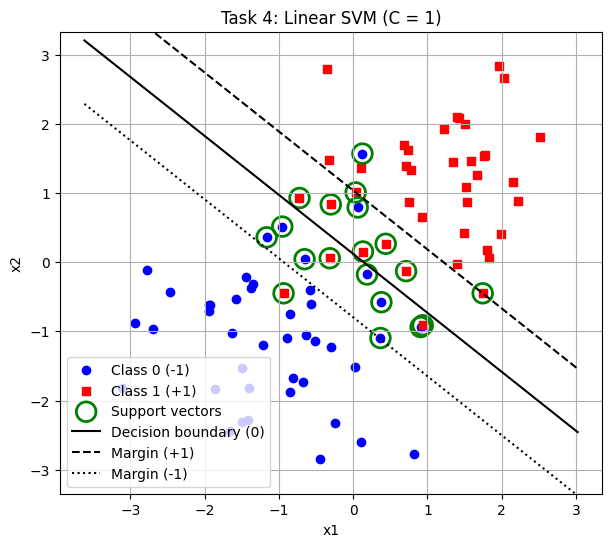


Logistic regression: w = [1.90777417 1.77614249]  b = -0.12840329206787948
SVM                : w = [0.92975193 1.09089862]  b = -0.13022629638276276
LR  normalised w: [0.73190565 0.68140598]
SVM normalised w: [0.64865561 0.76108206]
LR  b / ||w||   : -0.049261121702634074
SVM b / ||w||   : -0.09085436152882734


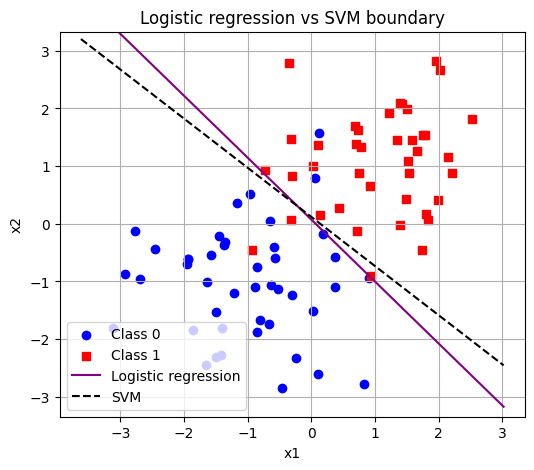

In [6]:
# Task 4
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

w_lr = w.copy()
b_lr = b

y_train_svm = 2 * y_train - 1
y_test_svm = 2 * y_test - 1
print("Unique SVM labels in train:", np.unique(y_train_svm))

svm = SVC(kernel="linear", C=1)
svm.fit(X_train, y_train_svm)

w_svm = svm.coef_[0]
b_svm = svm.intercept_[0]
print("SVM w =", w_svm)
print("SVM b =", b_svm)

print("Number of support vectors (per class):", svm.n_support_)
print("Total number of support vectors      :", len(svm.support_vectors_))

y_pred_train_svm = svm.predict(X_train)
y_pred_test_svm = svm.predict(X_test)

svm_train_accuracy = np.mean(y_pred_train_svm == y_train_svm)
svm_test_accuracy = np.mean(y_pred_test_svm == y_test_svm)

print("SVM training accuracy:", svm_train_accuracy)
print("SVM test accuracy    :", svm_test_accuracy)

margin_width = 2 / np.linalg.norm(w_svm)
print("Margin width 2/||w|| =", margin_width)

plt.figure(figsize=(7, 6))

plt.scatter(X_train[y_train_svm == -1, 0], X_train[y_train_svm == -1, 1],
            color="blue", marker="o", label="Class 0 (-1)")
plt.scatter(X_train[y_train_svm == 1, 0], X_train[y_train_svm == 1, 1],
            color="red", marker="s", label="Class 1 (+1)")

plt.scatter(svm.support_vectors_[:, 0], svm.support_vectors_[:, 1],
            s=200, facecolors="none", edgecolors="green", linewidths=2,
            label="Support vectors")

x1_line = np.linspace(X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5, 100)
x2_boundary = (0 - w_svm[0] * x1_line - b_svm) / w_svm[1]
x2_plus = (1 - w_svm[0] * x1_line - b_svm) / w_svm[1]
x2_minus = (-1 - w_svm[0] * x1_line - b_svm) / w_svm[1]

plt.plot(x1_line, x2_boundary, color="black", linestyle="-", label="Decision boundary (0)")
plt.plot(x1_line, x2_plus, color="black", linestyle="--", label="Margin (+1)")
plt.plot(x1_line, x2_minus, color="black", linestyle=":", label="Margin (-1)")

plt.ylim(X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Task 4: Linear SVM (C = 1)")
plt.legend()
plt.grid(True)
plt.savefig("task4_svm.png", dpi=300)
plt.show()

print("\nLogistic regression: w =", w_lr, " b =", b_lr)
print("SVM                : w =", w_svm, " b =", b_svm)

print("LR  normalised w:", w_lr / np.linalg.norm(w_lr))
print("SVM normalised w:", w_svm / np.linalg.norm(w_svm))
print("LR  b / ||w||   :", b_lr / np.linalg.norm(w_lr))
print("SVM b / ||w||   :", b_svm / np.linalg.norm(w_svm))

plt.figure(figsize=(6, 5))
plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], color="blue", marker="o", label="Class 0")
plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], color="red", marker="s", label="Class 1")
x2_lr = -(w_lr[0] * x1_line + b_lr) / w_lr[1]
plt.plot(x1_line, x2_lr, color="purple", label="Logistic regression")
plt.plot(x1_line, x2_boundary, color="black", linestyle="--", label="SVM")
plt.ylim(X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Logistic regression vs SVM boundary")
plt.legend()
plt.grid(True)
plt.savefig("task4_comparison.png", dpi=300)
plt.show()